# 06 · Evaluation and Packaging

1. **ML results summary** from notebook 02
2. **Retrieval quality** summary from notebooks 03 and 04
3. **13 curated assistant test queries** with **regression-like checks**: route correctness + output assertions
4. The **pytest** regression suite
5. Conclusions, assumptions and limitations

In [1]:
# --- setup: make the project package importable and show the run mode ---
import sys, os, json, warnings
from pathlib import Path
# library deprecation notices print install paths; hide them here and in parallel worker processes
os.environ["PYTHONWARNINGS"] = "ignore"; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src                                   # sets macOS OpenMP compatibility flags
from src import config
from src.llm import mode_label
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", palette="Set2"); plt.rcParams["figure.dpi"] = 110
OUT = config.OUTPUTS
print("Mode:", mode_label(), "| outputs ->", OUT.relative_to(ROOT))

Mode: LIVE (gpt-4o-mini + text-embedding-3-small) | outputs -> outputs


## 1. Classical ML results

In [2]:
sup = json.load(open(OUT / "supervised_summary.json"))
print("Supervised:", sup["model"], "| CV ROC-AUC", round(sup["cv_roc_auc"], 3), "| tuned threshold", round(sup["threshold"], 2))
print("Top drivers:", sup["top_drivers"])
display(pd.read_csv(OUT / "02_test_results.csv", index_col=0))
seg = json.load(open(OUT / "segment_summary.json"))
pd.DataFrame(seg["segments"])[["name", "share", "days_since_last_purchase", "total_orders", "avg_order_value", "purchase_rate", "discount_lift"]].round(3)

Supervised: Logistic Regression (L1, C=0.1) | CV ROC-AUC 0.64 | tuned threshold 0.34
Top drivers: ['membership_ord', 'income_ord', 'avg_product_rating', 'engagement', 'discount_amount']


,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
model,,,,,,
Dummy (majority),0.500,0.513,0.513,0.513,1.000,0.678
Logistic Regression,0.678,0.670,0.660,0.662,0.688,0.675
Random Forest,0.664,0.695,0.623,0.636,0.623,0.630
Gradient Boosting (HGB),0.676,0.696,0.630,0.629,0.682,0.654


,name,share,days_since_last_purchase,total_orders,avg_order_value,purchase_rate,discount_lift
0,Occasional Buyers,0.291,28.752,4.060,3007.032,0.523,0.009
1,Frequent Small-Basket Buyers,0.280,28.793,11.214,2694.217,0.540,0.137
2,High-Value Regulars,0.261,27.604,8.205,4799.833,0.486,0.054
3,Lapsing Customers,0.169,69.609,6.897,3609.219,0.494,0.023


## 2. Retrieval quality

In [3]:
display(pd.read_csv(OUT / "03_retrieval_inspection.csv"))
pe = pd.read_csv(OUT / "04_policy_retrieval.csv")
print(f"policy retrieval: hit@1 {pe['hit@1'].mean():.0%}, hit@3 {pe['hit@3'].mean():.0%} on {len(pe)} labelled questions")

,queries,exact_item_hit@5,sub_category_precision@5,colour_precision@5
0,300.0,0.66,0.927,1.0


policy retrieval: hit@1 100%, hit@3 100% on 10 labelled questions


## 3. Curated test queries with regression checks

In [4]:
from src.evaluation import run_suite, CASES
from src.llm import USAGE
res = run_suite(verbose=False)
print(f"PASS {res.PASS.sum()}/{len(res)} ({res.PASS.mean():.0%}) | routing correct {res.route_ok.mean():.0%} | "
      f"avg latency {res.latency_s.mean():.2f}s | LLM tokens {res.llm_tokens.sum()} | API usage {USAGE}")
res[["id", "query", "expected_tools", "routed_tools", "checks_passed", "failed_checks", "PASS", "latency_s"]]

PASS 13/13 (100%) | routing correct 100% | avg latency 0.03s | LLM tokens 5708 | API usage {'llm_calls': 0, 'cached_calls': 11, 'prompt_tokens': 0, 'completion_tokens': 0, 'embedding_tokens': 0}


,id,query,expected_tools,routed_tools,checks_passed,failed_checks,PASS,latency_s
0,Q1,Recommend casual sneakers under ₹4000 for daily wear.,product_search,product_search,3/3,,True,0.430
1,Q2,Can I return a discounted product after 7 days?,policy_qa,policy_qa,2/2,,True,0.003
2,Q3,Suggest products for a premium customer who prefers black formal shoes.,product_search,product_search,3/3,,True,0.001
3,Q4,Which customer segment seems most price-sensitive?,segment_insights,segment_insights,1/1,,True,0.000
4,Q5,Summarise the top three retrieved products and explain why they fit the query.,summarise_products,summarise_products,1/1,,True,0.000
5,Q6,How long does express delivery take?,policy_qa,policy_qa,2/2,,True,0.000
6,Q7,Is physical damage to my watch covered under the warranty?,policy_qa,policy_qa,2/2,,True,0.000
7,Q8,Show me a blue backpack for travel under 3000 and tell me if I can exchange it later.,"product_search,policy_qa","product_search,policy_qa",3/3,,True,0.001
8,Q9,What do customers say about Nike running shoes?,review_summary,review_summary,1/1,,True,0.001
9,Q10,When will my refund reach me if I paid by UPI?,policy_qa,policy_qa,1/1,,True,0.001


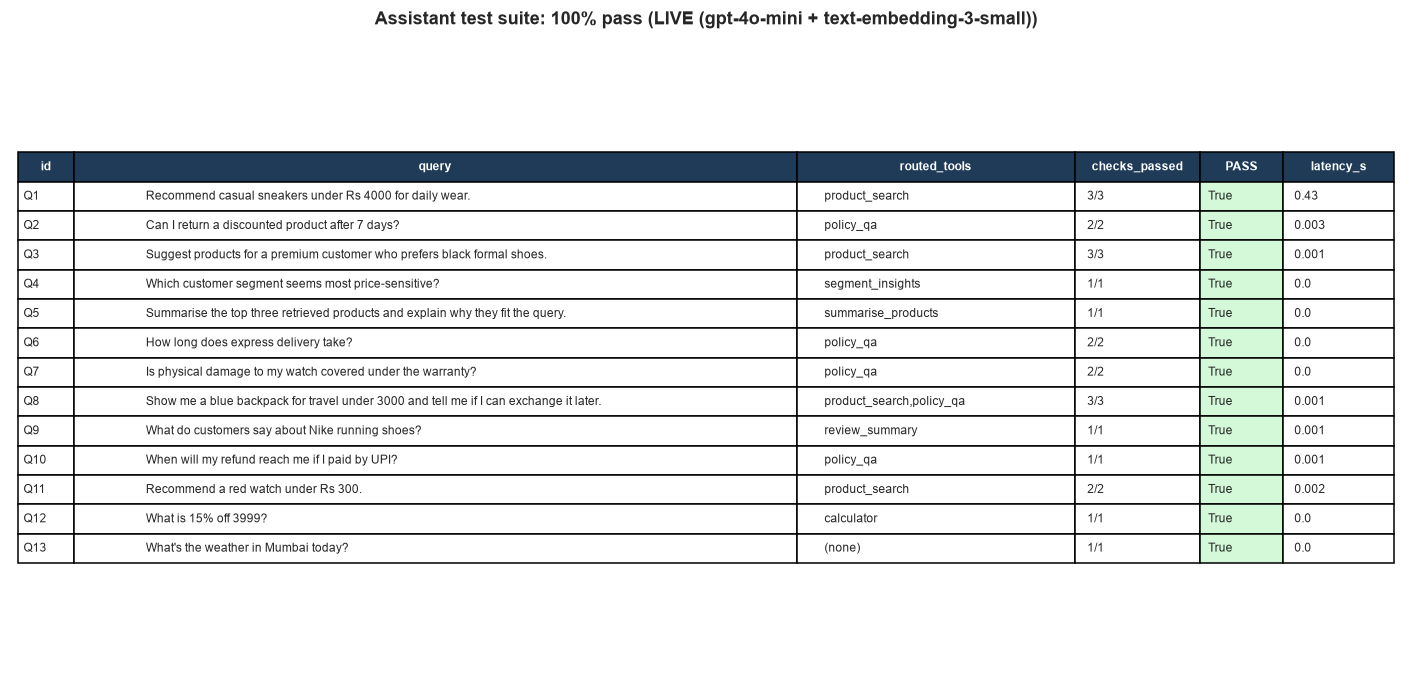

In [5]:
fig, ax = plt.subplots(figsize=(13, 0.42 * len(res) + 1)); ax.axis("off")
cols = ["id", "query", "routed_tools", "checks_passed", "PASS", "latency_s"]
tb = ax.table(cellText=res[cols].astype(str).replace("₹", "Rs ", regex=True).values, colLabels=cols, loc="center", cellLoc="left", colWidths=[.04, .52, .2, .09, .06, .08])
tb.auto_set_font_size(False); tb.set_fontsize(8); tb.scale(1, 1.35)
for (r, c), cell in tb.get_celld().items():
    if r == 0: cell.set_facecolor("#1f3b57"); cell.set_text_props(color="white", weight="bold")
    elif cols[c] == "PASS": cell.set_facecolor("#d3f9d8" if res.iloc[r - 1].PASS else "#ffe3e3")
ax.set_title(f"Assistant test suite: {res.PASS.mean():.0%} pass ({mode_label()})", weight="bold")
plt.tight_layout(); plt.savefig(OUT / "06_test_suite.png", dpi=130); plt.show()

In [6]:
# full answers for the five example queries from the brief
log = [json.loads(l) for l in open(OUT / "eval_log.jsonl")]
for r in log[:5]:
    print(f"[{r['id']}] {r['query']}\n{r['final_answer']}\n" + "-" * 100)

[Q1] Recommend casual sneakers under ₹4000 for daily wear.
Recommended products:
  - [ITM0845] Skechers Black Sneakers Synthetic Shoes - Rs 2,745: Designed for daily wear and offers comfort and style.
  - [ITM0905] Adidas Black Sneakers Synthetic Shoes - Rs 2,414: Suitable for daily wear with a good average rating of 4.3/5.
  - [ITM0851] Nike Grey Sneakers Mesh Shoes - Rs 1,919: Offers comfort and style for daily wear with a solid rating of 4.1/5.
  Why: All recommended sneakers are under ₹4000 and designed for daily wear, making them suitable for your request. They come from reputable brands and have positive customer feedback regarding comfort and style.
----------------------------------------------------------------------------------------------------
[Q2] Can I return a discounted product after 7 days?
Policy: It depends on the discount percentage. Returns are allowed within 7 days for unused products, but discounted products can only be returned if the discount is 30 percent or l

## 4. pytest regression suite (offline, deterministic)

In [7]:
import subprocess
t = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:warnings", str(ROOT / "tests")],
                   capture_output=True, text=True, cwd=ROOT)
print(t.stdout[-1200:])
json.dump({"suite_pass_rate": float(res.PASS.mean()), "suite_pass": int(res.PASS.sum()), "suite_total": len(res),
           "routing_accuracy": float(res.route_ok.mean()), "pytest": t.stdout.strip().splitlines()[-1] if t.stdout else "n/a",
           "mode": mode_label(), "usage": USAGE}, open(OUT / "evaluation_summary.json", "w"), indent=2)

.......................                                                  [100%]
23 passed in 1.64s



## 5. Conclusions

**What works**
- A clean, leakage-aware ML pipeline. Conversion is driven mainly by **membership tier, income band and product rating**. Price and discount matter little *on average*.
- The RFM segmentation shows **where** discounts work: the *Frequent Small-Basket Buyers* convert about 14 points more on deep discounts, while the other segments barely react. Two complementary views for the business.
- Product recommendations come only from retrieved items, with budget and attributes enforced as hard filters and a validator that removes anything ungrounded.
- Policy answers cite `policy_doc_id`, quote the rule verbatim, and refuse when the policies are silent.
- The controller is simple and fully traceable. It handles multi-intent queries, session memory and guardrails, with at most 3 tool calls per query.

**Assumptions**
- Each interaction row is one catalogue item and one customer snapshot, because the source ids are not stable keys.
- The template-generated text columns and the 5 provided policies are treated as the store's real content. No policy text was invented.
- Prices are in INR, and stock above 0 means the item can be recommended.

**Limitations and next steps**
- The tabular signal is modest (ROC-AUC about 0.65-0.68). Real clickstream data (sessions, previous views) would help most.
- The segments are only moderately separated (silhouette about 0.26).
- The review text is templated (28 variants), so review summaries are generic.
- The image column has no files, so the optional multimodal extension was not attempted.
- Next steps: a reranker for retrieval, an LLM-as-judge groundedness score, and A/B testing segment-specific discount strategies.